In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update(
    {
        "font.size": 10,
        "axes.titlesize": 14,
        "axes.labelsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        # embed TrueType fonts in PDF for consistent rendering
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        # use Computer Modern (mathtext + serif fallback)
        "font.family": "serif",
        "font.serif": ["Computer Modern", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        # avoid requiring an external TeX installation by using mathtext
        "text.usetex": False,
    }
)

In [2]:
import os

import jax
import jax.numpy as jnp

os.environ["CUDA_VISIBLE_DEVICES"] = "3"

HORIZON = 50
INITIAL_STATE = jnp.array(
    [0.0, 0.0, 0.0, 1.0]
)  # x, y, theta, v, heading right at 1 m/s

In [3]:
from hcnn.system_dynamics import SystemDynamicsBike

sys_dynamics = SystemDynamicsBike.factory(wheelbase=1.0, dt=0.4)

In [4]:
from flax import struct

from hcnn.system_constraints import SystemConstraintsBase


@struct.dataclass
class SystemConstraintsSlalom(SystemConstraintsBase):
    state_dim: int
    action_dim: int
    constraint_dim: int
    lower_bound: jax.Array
    upper_bound: jax.Array
    center1: jax.Array
    radius1: float
    center2: jax.Array
    radius2: float
    center3: jax.Array
    radius3: float

    @classmethod
    def factory(cls):
        return cls(
            state_dim=4,
            action_dim=2,
            constraint_dim=4,
            lower_bound=jnp.array([1.0, 1.0, 1.0, -0.6]),
            upper_bound=jnp.array([jnp.inf, jnp.inf, jnp.inf, +0.6]),
            center1=jnp.array([05.0, -0.2]),
            radius1=1.0,
            center2=jnp.array([10.0, +0.2]),
            radius2=1.0,
            center3=jnp.array([15.0, -0.2]),
            radius3=1.0,
        )

    def __call__(self, state: jax.Array, action: jax.Array) -> jax.Array:
        state_xy = state[..., 0:2]
        # keep steering as a trailing dimension so concatenation shapes match
        steering_angle = action[..., 1:2]

        diff1 = state_xy - self.center1
        val1 = jnp.sum(diff1 * diff1, axis=-1, keepdims=True) - (
            self.radius1 * self.radius1
        )

        diff2 = state_xy - self.center2
        val2 = jnp.sum(diff2 * diff2, axis=-1, keepdims=True) - (
            self.radius2 * self.radius2
        )

        diff3 = state_xy - self.center3
        val3 = jnp.sum(diff3 * diff3, axis=-1, keepdims=True) - (
            self.radius3 * self.radius3
        )

        return jnp.concatenate([val1, val2, val3, steering_angle], axis=-1)


sys_constraints = SystemConstraintsSlalom.factory()

In [5]:
from hcnn.optimization_layer import Rollout


def scan_fn(state, _):
    action = jnp.array([0.0, 0.0])  # no steering, no acceleration
    next_state = sys_dynamics(state, action)
    return next_state, (state, action)


states, actions = jax.lax.scan(scan_fn, INITIAL_STATE, None, length=HORIZON)[1]

raw_rollout = Rollout(states, actions)

In [6]:
raw_rollout.states[-1]

Array([19.59999,  0.     ,  0.     ,  1.     ], dtype=float32)

In [7]:
from hcnn.optimization_layer import ProjectionPhi, ProjectionProblem
from hcnn.solver import SQPParameters

projection_problem = ProjectionProblem.factory(
    sys_dynamics=sys_dynamics,
    sys_constraints=sys_constraints,
    horizon=HORIZON,
    projection_relaxation_penalty=1e3,
)
phi = ProjectionPhi(
    states_ref=raw_rollout.states,
    actions_ref=raw_rollout.actions,
    initial_state=INITIAL_STATE,
)
sqp_problem = projection_problem.replace(phi=phi)
sqp_parameters = SQPParameters(
    alpha=1.6,
    sigma=0.1,
    rho=0.1,
    rho_equality_mult=1e3,
    tol_prim=1e-2,
    tol_dual=1e-2,
    tol_osqp=1e-3,
    epsilon=1e-12,
    max_iter_lin=2000,
    max_iter_nonlin=20,
)

In [8]:
# Manual SQP iterations to log residuals
from functools import partial

import jax.numpy as jnp

from hcnn.solver.solver_sqp import SQPVariables, sqp_step

# Initialize SQP variables
variables = SQPVariables.factory(problem=sqp_problem, parameters=sqp_parameters)

# Lists to store residuals
primal_residuals = []
dual_residuals = []

step_jit = jax.jit(
    partial(sqp_step, problem=sqp_problem, parameters=sqp_parameters)
)

for i in range(sqp_parameters.max_iter_nonlin):
    print(f"Iteration {i + 1}")
    variables = step_jit(variables)
    primal_residuals.append(variables.max_primal_residual)
    dual_residuals.append(variables.max_dual_residual)

# Convert lists to JAX arrays for plotting
primal_residuals = jnp.stack(primal_residuals)
dual_residuals = jnp.stack(dual_residuals)

# Extract final solution
x_star_manual = variables.x
optvar = projection_problem.x_to_optvar(x_star_manual)
proj_rollout = Rollout(
    states=optvar.states,
    actions=optvar.actions,
)

Iteration 1
Iteration 2
Iteration 3
Iteration 4
Iteration 5
Iteration 6
Iteration 7
Iteration 8
Iteration 9
Iteration 10
Iteration 11
Iteration 12
Iteration 13
Iteration 14
Iteration 15
Iteration 16
Iteration 17
Iteration 18
Iteration 19
Iteration 20


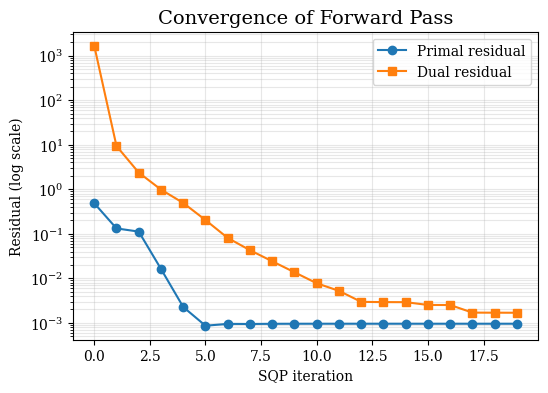

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(primal_residuals, label="Primal residual", marker="o")
ax.plot(dual_residuals, label="Dual residual", marker="s")
ax.set_yscale("log")
ax.set_xlabel("SQP iteration")
ax.set_ylabel("Residual (log scale)")
ax.set_title("Convergence of Forward Pass")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()
fig.savefig("convergence_bike.pdf")

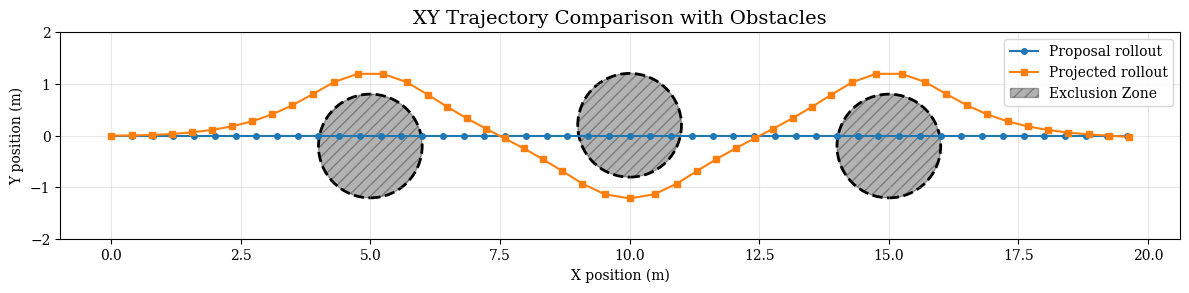

In [10]:
raw_xy = raw_rollout.states[:, :2]
proj_xy = proj_rollout.states[:, :2]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    raw_xy[:, 0],
    raw_xy[:, 1],
    "o-",
    label="Proposal rollout",
    markersize=4,
    linewidth=1.5,
)
ax.plot(
    proj_xy[:, 0],
    proj_xy[:, 1],
    "s-",
    label="Projected rollout",
    markersize=4,
    linewidth=1.5,
)

# draw circular obstacles
obstacle_label = False
for center, radius in [
    (sys_constraints.center1, sys_constraints.radius1),
    (sys_constraints.center2, sys_constraints.radius2),
    (sys_constraints.center3, sys_constraints.radius3),
]:
    label = "Exclusion Zone" if not obstacle_label else ""
    circle = plt.Circle(
        tuple(center),
        radius,
        color="k",
        fill=True,
        alpha=0.3,
        label=label,
        hatch="///",
    )
    ax.add_patch(circle)

    # Also add the boundary circle
    circle_boundary = plt.Circle(
        tuple(center),
        radius,
        color="k",
        fill=False,
        linewidth=2,
        linestyle="--",
    )
    ax.add_patch(circle_boundary)
    obstacle_label = True

ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_title("XY Trajectory Comparison with Obstacles")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_aspect("equal")

# increase y-axis range to [-2, 2]
ax.set_ylim(-2, 2)

plt.tight_layout()
plt.show()
fig.savefig("trajectory_bike.pdf")

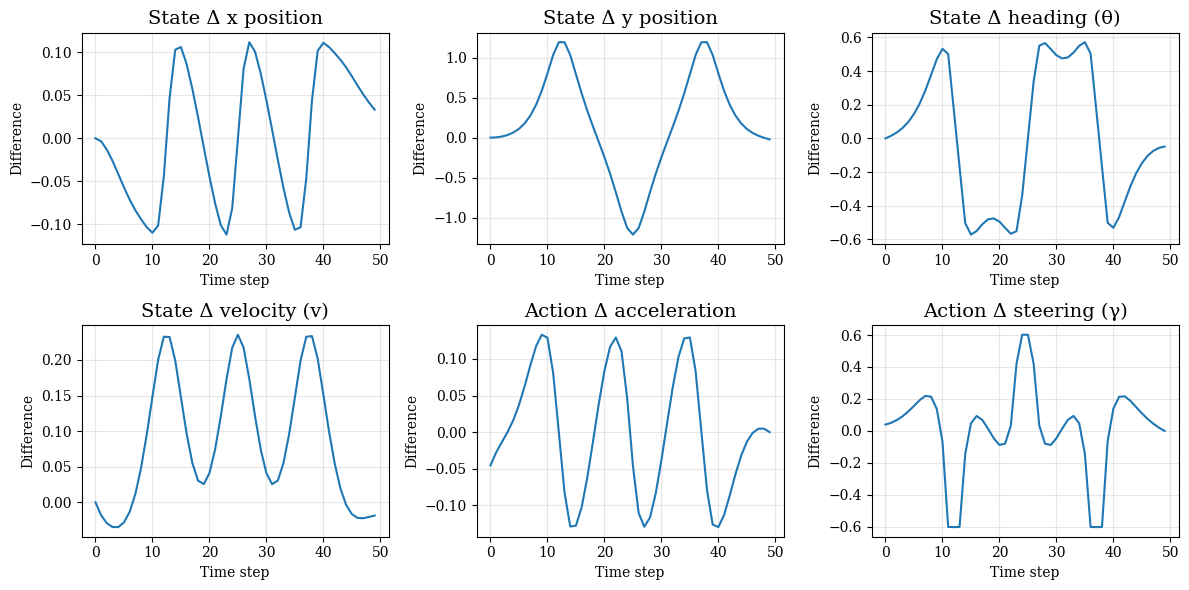

In [11]:
# compute differences between projected and raw rollouts
state_diff = proj_rollout.states - raw_rollout.states
action_diff = proj_rollout.actions - raw_rollout.actions

time = jnp.arange(HORIZON)

# prepare subplots: 4 state dims + 2 action dims
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
state_labels = ["x position", "y position", "heading (θ)", "velocity (v)"]
action_labels = ["acceleration", "steering (γ)"]

# plot state differences
for i in range(4):
    ax = axs.flat[i]
    ax.plot(time, state_diff[:, i])
    ax.set_title(f"State Δ {state_labels[i]}")
    ax.set_xlabel("Time step")
    ax.set_ylabel("Difference")
    ax.grid(True, alpha=0.3)

# plot action differences
for i in range(2):
    ax = axs.flat[4 + i]
    ax.plot(time, action_diff[:, i])
    ax.set_title(f"Action Δ {action_labels[i]}")
    ax.set_xlabel("Time step")
    ax.set_ylabel("Difference")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
fig.savefig("trajectory_diff_bike.pdf")

In [12]:
x_star = variables.x
y_star = variables.y
q_plus_s = variables.q_plus_s
problem = sqp_problem
parameters = sqp_parameters

In [13]:
tangent = jax.tree_util.tree_map(
    lambda x: jax.random.normal(jax.random.key(0), x.shape), phi
)
cotangent = jax.tree_util.tree_map(
    lambda x: jax.random.normal(jax.random.key(1), x.shape), x_star
)

In [14]:
# Calculate numerical JVP for gradient verification
# This implements the same numerical differentiation as JAX's check_vjp

eps = 3 * parameters.tol_prim  # finite difference step size


def numerical_jvp(f, primals, tangents, eps=eps):
    """Compute JVP using finite differences: [f(x + ε·v) - f(x - ε·v)] / (2ε)"""

    # Scale tangents by eps
    def scalar_mul(tree, scalar):
        return jax.tree_util.tree_map(lambda x: x * scalar, tree)

    def tree_add(tree1, tree2):
        return jax.tree_util.tree_map(lambda x, y: x + y, tree1, tree2)

    def tree_sub(tree1, tree2):
        return jax.tree_util.tree_map(lambda x, y: x - y, tree1, tree2)

    delta = scalar_mul(tangents, eps)
    f_pos = f(tree_add(primals, delta))
    f_neg = f(tree_sub(primals, delta))
    return scalar_mul(tree_sub(f_pos, f_neg), 0.5 / eps)


# Define the function we want to differentiate
# This should be the projection function from phi to x_star
def projection_fn(phi_input):
    """Function that takes phi and returns the optimized x"""
    # Create a new projection problem with the input phi
    temp_problem = projection_problem.replace(phi=phi_input)

    # Initialize SQP variables for this problem
    temp_variables = SQPVariables.factory(
        problem=temp_problem, parameters=sqp_parameters
    )

    # Run SQP optimization
    step_fn = jax.jit(
        partial(sqp_step, problem=temp_problem, parameters=sqp_parameters)
    )

    for _ in range(sqp_parameters.max_iter_nonlin):
        temp_variables = step_fn(temp_variables)

    return temp_variables.x


# Calculate numerical JVP
tangent_out = numerical_jvp(projection_fn, phi, tangent, eps=eps)

In [15]:
v1 = cotangent

## Precompute JVP, VJP and HVP for the constraint function
# h_jvp computes v -> dh/dx @ v
h, h_jvp = jax.linearize(problem.constraint_fn, x_star)
# h_vjp computes w -> w^T @ dh/dx
_, h_vjp = jax.vjp(problem.constraint_fn, x_star)

## Implicit VJP (step 1)
reg = 10 * parameters.tol_prim
y_plus = jnp.maximum(y_star, 0.0)
y_minus = jnp.maximum(-y_star, 0.0)

frac_upper = y_plus / (reg + problem.upper_bound - h)
frac_lower = y_minus / (reg + h - problem.lower_bound)
frac_sum = frac_upper + frac_lower


def schur_lhs(u1: jax.Array) -> jax.Array:
    return q_plus_s * u1 + h_vjp(frac_sum * h_jvp(u1))[0]


u1, _ = jax.scipy.sparse.linalg.bicgstab(A=schur_lhs, b=-v1)

jvp_u1 = h_jvp(u1)
u2 = jvp_u1 / (reg + problem.upper_bound - h)
u3 = jvp_u1 / (problem.lower_bound - reg - h)

## Explicit VJP (step 2)
## phi
g_phi_d_1 = jax.grad(
    lambda phi_arg: jnp.dot(
        jax.jvp(
            lambda x_inner: problem.constraint_fn_phi(x_inner, phi_arg),
            (x_star,),
            (u1,),
        )[1],
        y_star,
    ),
)(problem.phi)

g_phi_d_2 = jax.vjp(
    lambda phi_arg: problem.constraint_fn_phi(x_star, phi_arg),
    problem.phi,
)[1](u2 * y_plus - u3 * y_minus)[0]
cotangent_out = jax.tree_util.tree_map(jnp.add, g_phi_d_1, g_phi_d_2)

jnp.mean(schur_lhs(u1) / -v1)

Array(0.99999845, dtype=float32)

In [16]:
# Calculate inner products for gradient verification
# This follows the same approach as JAX's check_vjp function


def inner_prod(xs, ys):
    """Compute inner product between two pytrees"""

    def contract(x, y):
        return jnp.real(jnp.dot(jnp.conj(x).reshape(-1), y.reshape(-1)))

    return jax.tree_util.tree_reduce(
        jnp.add, jax.tree_util.tree_map(contract, xs, ys)
    )


# The key mathematical relationship we're verifying:
# ⟨tangent, VJP(cotangent)⟩ = ⟨JVP(tangent), cotangent⟩

ip = inner_prod(tangent, cotangent_out)
ip_expected = inner_prod(tangent_out, cotangent)

print(f"Inner product (tangent, VJP(cotangent)): {ip:.6f}")
print(f"Inner product (JVP(tangent), cotangent): {ip_expected:.6f}")
print(f"Difference: {jnp.abs(ip - ip_expected):.6e}")

Inner product (tangent, VJP(cotangent)): -3.410467
Inner product (JVP(tangent), cotangent): -1.207291
Difference: 2.203176e+00


In [17]:
# Analysis of BiCGSTAB convergence in backward pass
# Track ⟨tangent, VJP(cotangent)⟩ = ⟨JVP(tangent), cotangent⟩ for different bicgstab iterations
bicgstab_iterations = jnp.arange(0, 210, 10)

inner_products_vjp = []
inner_products_jvp = []
differences = []

# Store the expected value (from numerical JVP) for comparison
ip_numerical = inner_prod(tangent_out, cotangent)

for max_iter in bicgstab_iterations:
    # Solve the Schur complement system with limited iterations
    u1_iter, info = jax.scipy.sparse.linalg.bicgstab(
        A=schur_lhs,
        b=-v1,
        maxiter=int(max_iter),
    )

    jvp_u1_iter = h_jvp(u1_iter)
    u2_iter = jvp_u1_iter / (reg + problem.upper_bound - h)
    u3_iter = jvp_u1_iter / (problem.lower_bound - reg - h)

    # Compute VJP result with this u1
    g_phi_d_1_iter = jax.grad(
        lambda phi_arg: jnp.dot(
            jax.jvp(
                lambda x_inner: problem.constraint_fn_phi(x_inner, phi_arg),
                (x_star,),
                (u1_iter,),
            )[1],
            y_star,
        ),
    )(problem.phi)

    g_phi_d_2_iter = jax.vjp(
        lambda phi_arg: problem.constraint_fn_phi(x_star, phi_arg),
        problem.phi,
    )[1](u2_iter * y_plus - u3_iter * y_minus)[0]

    cotangent_out_iter = jax.tree_util.tree_map(
        jnp.add, g_phi_d_1_iter, g_phi_d_2_iter
    )

    # Calculate inner products
    ip_vjp = inner_prod(tangent, cotangent_out_iter)
    ip_jvp = (
        ip_numerical  # This stays constant (from numerical differentiation)
    )
    diff = jnp.abs(ip_vjp - ip_jvp)

    inner_products_vjp.append(ip_vjp)
    inner_products_jvp.append(ip_jvp)
    differences.append(diff)

    print(
        f"Iter {max_iter:2d}: VJP={ip_vjp:.6f}, JVP={ip_jvp:.6f}, Diff={diff:.6e}"
    )

# Convert to JAX arrays for plotting
inner_products_vjp = jnp.array(inner_products_vjp)
inner_products_jvp = jnp.array(inner_products_jvp)
differences = jnp.array(differences)

print(f"Difference: {differences[-1]:.6e}")

Iter  0: VJP=0.000000, JVP=-1.207291, Diff=1.207291e+00
Iter 10: VJP=8.179467, JVP=-1.207291, Diff=9.386758e+00
Iter 20: VJP=4.567134, JVP=-1.207291, Diff=5.774425e+00
Iter 30: VJP=2.086447, JVP=-1.207291, Diff=3.293738e+00
Iter 40: VJP=1.378404, JVP=-1.207291, Diff=2.585694e+00
Iter 50: VJP=0.925015, JVP=-1.207291, Diff=2.132306e+00
Iter 60: VJP=0.199887, JVP=-1.207291, Diff=1.407178e+00
Iter 70: VJP=-0.911125, JVP=-1.207291, Diff=2.961653e-01
Iter 80: VJP=-1.511894, JVP=-1.207291, Diff=3.046033e-01
Iter 90: VJP=-1.939892, JVP=-1.207291, Diff=7.326014e-01
Iter 100: VJP=-2.236421, JVP=-1.207291, Diff=1.029130e+00
Iter 110: VJP=-2.208564, JVP=-1.207291, Diff=1.001273e+00
Iter 120: VJP=-2.661338, JVP=-1.207291, Diff=1.454047e+00
Iter 130: VJP=-2.803700, JVP=-1.207291, Diff=1.596410e+00
Iter 140: VJP=-3.201184, JVP=-1.207291, Diff=1.993893e+00
Iter 150: VJP=-3.509133, JVP=-1.207291, Diff=2.301842e+00
Iter 160: VJP=-3.939448, JVP=-1.207291, Diff=2.732158e+00
Iter 170: VJP=-3.919247, JVP=-1

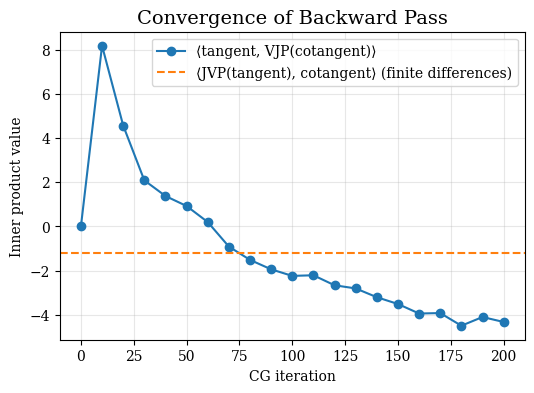

In [18]:
# Plot convergence in backward pass
fig, ax = plt.subplots(figsize=(6, 4))

# Inner products comparison
ax.plot(
    bicgstab_iterations,
    inner_products_vjp,
    "o-",
    color="C0",
    label=r"⟨tangent, VJP(cotangent)⟩",
)
ax.axhline(
    y=ip_numerical,
    color="C1",
    linestyle="--",
    label=r"⟨JVP(tangent), cotangent⟩ (finite differences)",
)
ax.set_xlabel("CG iteration")
ax.set_ylabel("Inner product value")
ax.set_title("Convergence of Backward Pass")
ax.legend()
ax.grid(True, alpha=0.3)


plt.show()
fig.savefig("convergence_bike_bwd.pdf")
